# 2 次のローパスフィルタ(サレン・キー)

コンデンサを 2 個使った **2 次の LPF** です。[1 次の LPF](../02_filter1st/01_lpf.ipynb) より高い周波数を強く落とし(40 dB/decade)、さらに **Q** という値で、カットオフ周波数の近くの形を変えられます。

この回では、$f_c$ でのゲインが Q になること、Q によるボード線図の違い、方形波を入れたときの行き過ぎと振動を見ます。

## 回路

![サレン・キーの LPF](01_sk_lpf/circuit.svg)

**サレン・キー**(Sallen-Key)回路のうち、オペアンプをボルテージフォロワ(ゲイン 1)にした形です。抵抗 2 本は同じ値 R にします。C1 は出力に、C2 は信号のグランド(単電源では 2.5 V、Mimic の Vref)につなぎます。

## 原理

RC が 2 段になっていて、C1 から出力の電圧を戻しています(正帰還)。この戻しの強さで、$f_c$ 付近のふくらみ(Q)が決まります。

$$H(f) = \frac{1}{1 - (f/f_c)^2 + j\,\dfrac{f/f_c}{Q}}, \qquad f_c = \frac{1}{2\pi R\sqrt{C_1 C_2}}, \qquad Q = \frac{1}{2}\sqrt{\frac{C_1}{C_2}}$$

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | 1 | 0° |
| $f = f_c$ | **Q** | −90° |
| $f \gg f_c$ | $(f_c / f)^2$(周波数が 10 倍で 1/100、−40 dB/dec) | −180° に近づく |

**Q の意味**:Q が大きいほど $f_c$ の近くがふくらみ、方形波を入れると行き過ぎて振動します。よく使う値には名前があります。

| Q | 名前 | 特徴 |
|---|---|---|
| 0.5 | (RC 2 段と同じ) | ふくらみも行き過ぎもない |
| 0.577 | ベッセル | 波形の形をくずしにくい |
| 0.707 | バターワース | 通す帯域がいちばん平ら |
| 1 以上 | (チェビシェフなど) | $f_c$ の近くがふくらむ。急に落ちる |

![2 次の LPF の周波数特性(模式図)](01_sk_lpf/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路(R が同じ値) |
|---|---|---|
| `lab.mimic.biquad_lpf(fc, q)` | `mimic.setFilterBiquadLPF(fc, Q)` | $C_1 = \dfrac{2Q}{2\pi f_c R}$、$C_2 = \dfrac{1}{2Q \cdot 2\pi f_c R}$ |

`q` を省くとバターワース(0.707)です。ライブラリには `MIMIC_FILTER_Q_BESSEL`、`MIMIC_FILTER_Q_BUTTERWORTH`、`MIMIC_FILTER_Q_CHEBYSHEV`(1.0)の定数があります。Q は 0.1〜10 の範囲で設定できます。

例:$f_c$ = 100 Hz、Q = 0.707 は、R = 10 kΩ、C1 = 225 nF、C2 = 113 nF の回路にあたります。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # cutoff frequency [Hz]

def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2


def second_order(f, fc, q, kind):
    # Response of the module: lpf 1/D, hpf s^2/D, bpf (s/Q)/D, notch (s^2 + 1)/D
    s = 1j * f / fc
    d = s * s + s / q + 1
    return {"lpf": 1, "hpf": s * s, "bpf": s / q, "notch": s * s + 1}[kind] / d

## 実験 1:$f_c$ でのゲインは Q

Q = 2 にして、$f_c$ の正弦波を入れます。振幅が 2 倍、位相が 90° 遅れるはずです。入力より出力のほうが大きくなるのは、1 次のフィルタにはなかった性質です。

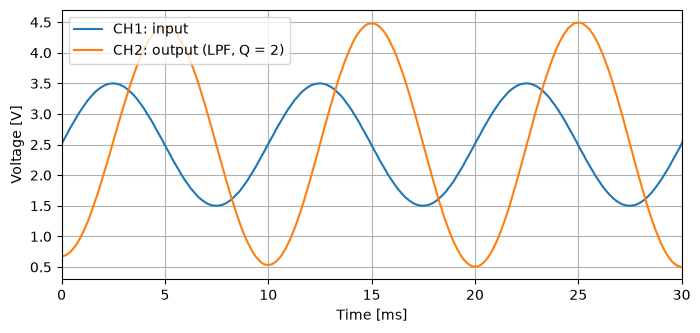

gain : 1.986   (theory 2 = Q)
phase: -90.8 deg (theory -90)


In [3]:
lab.mimic.biquad_lpf(FC, 2)
lab.fg.sine(FC, 1.0)
t, ch1, ch2 = lab.scope.capture(2000)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (LPF, Q = 2)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, FC)
a2, p2, c2 = fit_sine(t, ch2, FC)
print(f"gain : {a2 / a1:.3f}   (theory 2 = Q)")
print(f"phase: {(p2 - p1 + 180) % 360 - 180:.1f} deg (theory -90)")

## 実験 2:Q を変えたボード線図

Q = 0.5、0.707、2 でボード線図を測り、理論と比べます。破線は 1 次の LPF(同じ $f_c$)です。高い周波数で、2 次のほうが傾きが 2 倍(−40 dB/decade)になっています。1 つの Q に 10 秒ほどかかります。

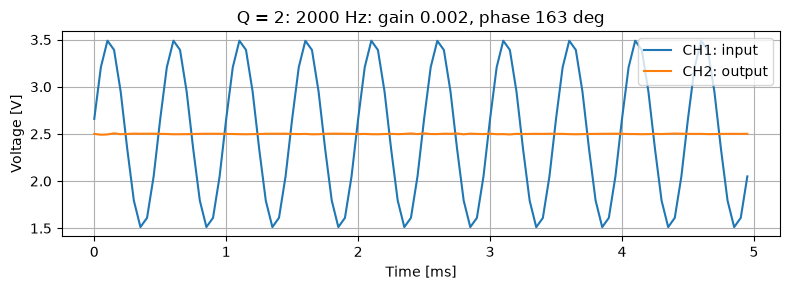

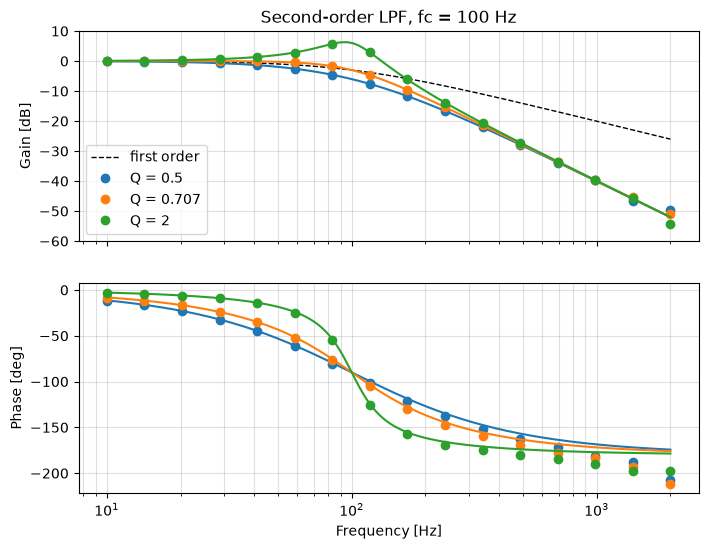

In [4]:
freqs = np.logspace(1, np.log10(2000), 16)   # 10 Hz - 2 kHz
f_th = np.logspace(1, np.log10(2000), 200)
fig, ax1, ax2 = bode_axes(f"Second-order LPF, fc = {FC} Hz")
h1 = 1 / (1 + 1j * f_th / FC)
ax1.semilogx(f_th, 20 * np.log10(abs(h1)), "k--", lw=1, label="first order")
rs = {}
mon = Monitor()  # one plot updated while measuring
for i, q in enumerate([0.5, 0.707, 2]):
    lab.mimic.biquad_lpf(FC, q)
    r = rs[q] = lab.frequency_response(freqs, monitor=mon, label=f"Q = {q}: ")
    h = second_order(f_th, FC, q, "lpf")
    ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", color=f"C{i}")
    ax2.semilogx(f_th, np.degrees(np.unwrap(np.angle(h))), "-", color=f"C{i}")
    ax1.semilogx(r.freq, r.gain_db, "o", color=f"C{i}", label=f"Q = {q}")
    ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.unwrap(np.angle(second_order(r.freq, FC, q, "lpf"))))), "o", color=f"C{i}")
ax1.set_ylim(-60, 10)
ax1.legend()
mon.close()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


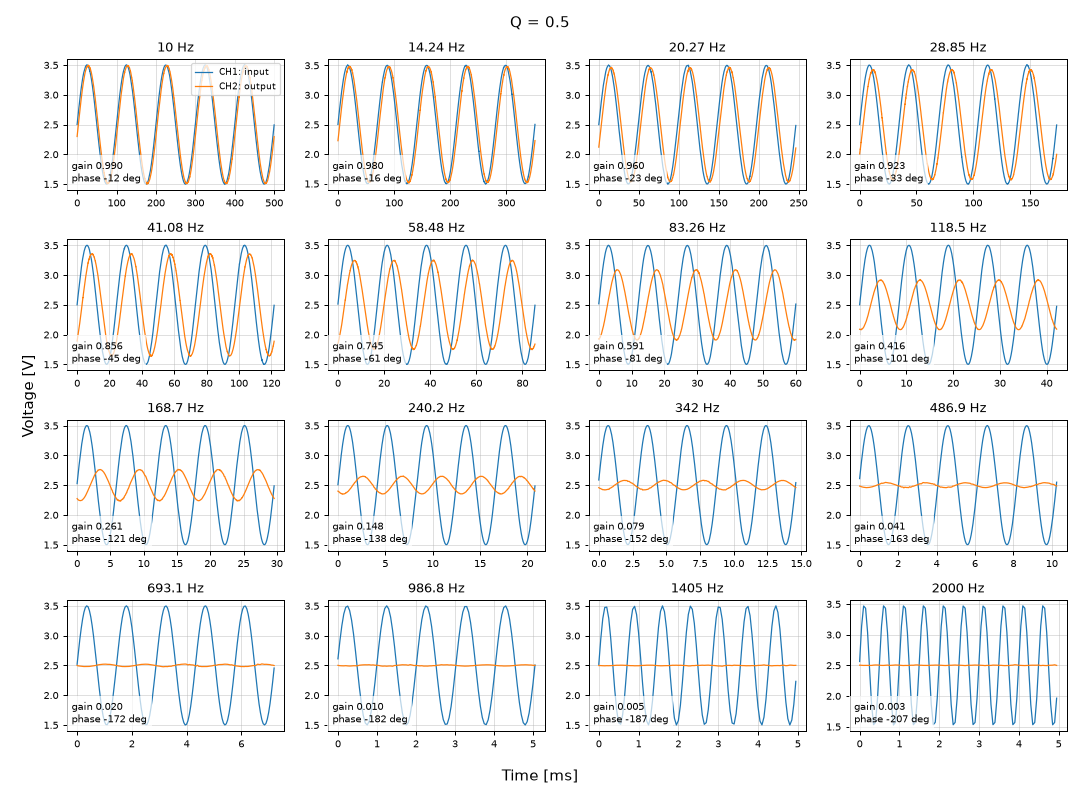


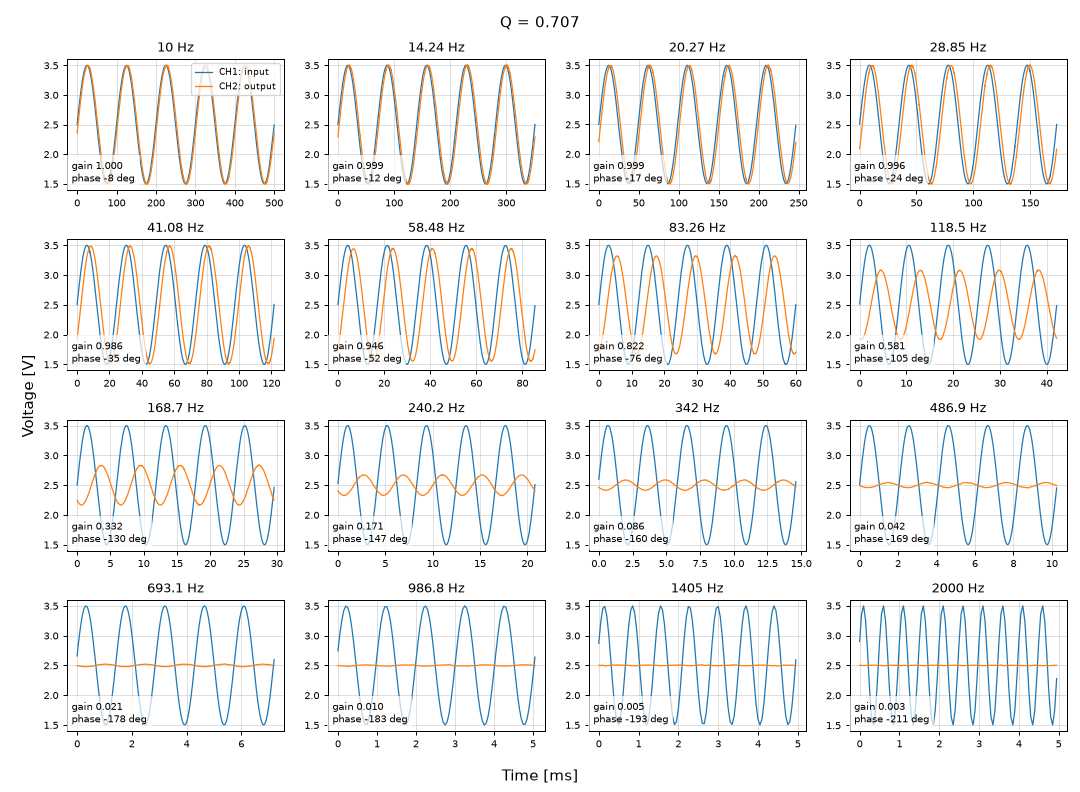


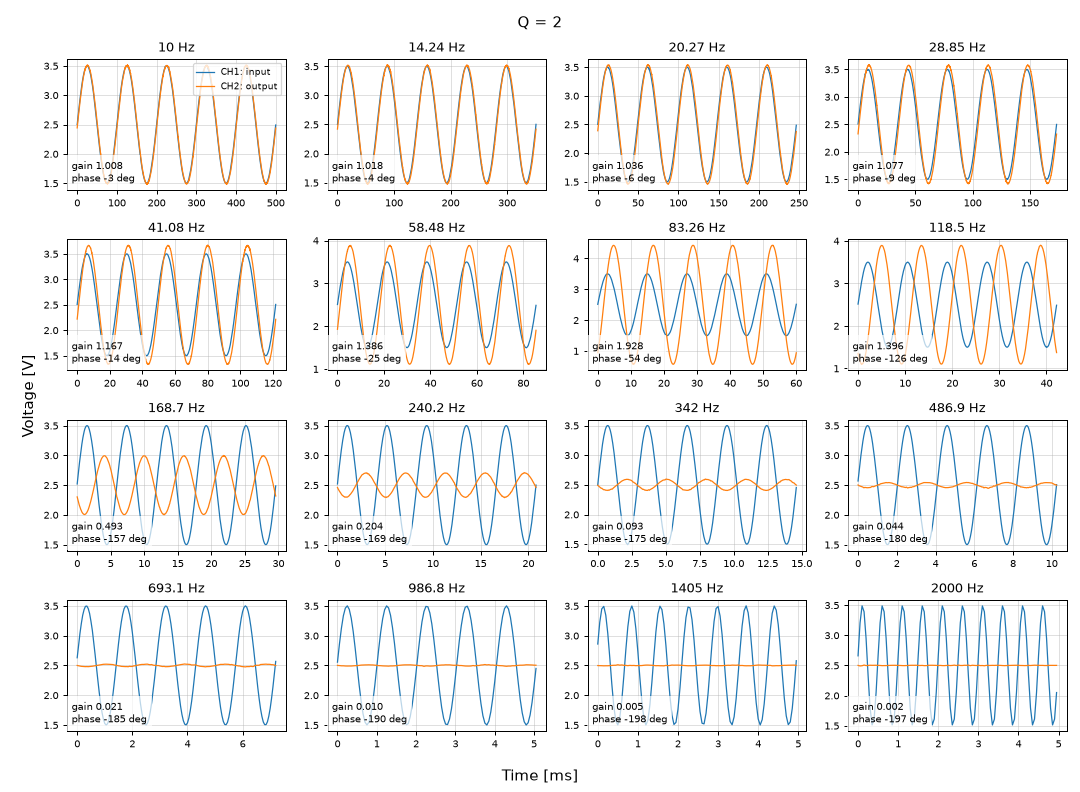

In [5]:
for key, r in rs.items():
    plot_waveforms(r, title=f"Q = {key}", collapsed=True)

点が測定、線が理論です。高い周波数で位相が理論より遅れるのは、Mimic の遅れのためです([周波数特性を測る回](../02_filter1st/03_bode.ipynb))。

## 実験 3:方形波を入れる(行き過ぎと振動)

20 Hz の方形波を入れます。Q が大きいほど、切り替わりのあとで出力が行き過ぎ(オーバーシュート)、$f_c$ に近い周波数で振動してから落ち着きます。

Q = 0.5: overshoot 0 %
Q = 0.707: overshoot 4 %
Q = 2: overshoot 44 %


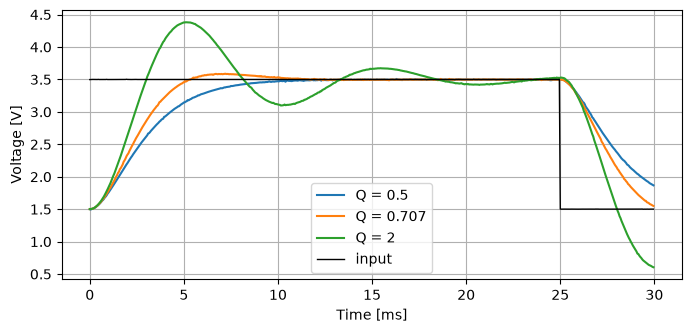

In [6]:
lab.fg.square(20, 1.0)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, q in enumerate([0.5, 0.707, 2]):
    lab.mimic.biquad_lpf(FC, q)
    t, ch1, ch2 = lab.scope.capture(600)  # 30 ms: the falling edge is at 25 ms
    ax.plot(t * 1e3, ch2, color=f"C{i}", label=f"Q = {q}")
    high = ch1[t < 0.024].mean()   # input after the rising edge at t = 0
    low = ch1[t > 0.026].mean()    # input after the falling edge
    over = (ch2[t < 0.025].max() - high) / (high - low) * 100
    print(f"Q = {q}: overshoot {over:.0f} %")
ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

理論上の行き過ぎは、Q = 0.5 で 0 %、0.707 で 4 %、2 で 44 % です。波形の形をくずしたくないときは Q を小さく(ベッセルなど)、通す帯域を平らにしたいときはバターワースを選びます。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. Q を変えて方形波を入れる
<details><summary>ヒント</summary>

`Q_TRY` を 0.577 → 1 → 5 と変えてみましょう。ベッセル(0.577)は行き過ぎがほとんどなく(約 0.4 %)、形がきれいに保たれます。Q = 5 では大きく行き過ぎ、長いあいだ振動が続きます。行き過ぎの理論値は $\exp\!\left(-\pi/\sqrt{4Q^2 - 1}\right)$ です(Q > 0.5)。

</details>

overshoot 0.9 % (theory 0.4 %)


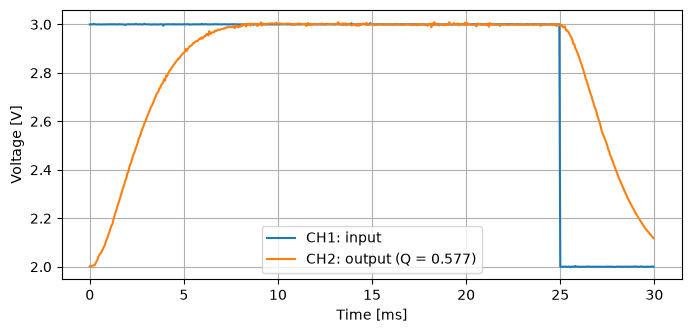

In [7]:
Q_TRY = 0.577

import time
lab.mimic.biquad_lpf(FC, Q_TRY)
lab.fg.square(20, 0.5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(600)   # 30 ms
high, low = ch1[t < 0.024].mean(), ch1[t > 0.026].mean()
print(f"overshoot {(ch2[t < 0.025].max() - high) / (high - low) * 100:.1f} % "
      f"(theory {100 * np.exp(-np.pi / np.sqrt(4 * Q_TRY ** 2 - 1)) if Q_TRY > 0.5 else 0:.1f} %)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (Q = {Q_TRY})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 振動の周波数を数える

Q を大きくして方形波を入れ、振動の山と山の間隔から、振動の周波数を求めます。$f_c$ と比べてみます。
<details><summary>ヒント</summary>

`Q_RING` を 2 → 5 → 10 と変えてみましょう。振動の周波数は $f_c\sqrt{1 - 1/(4Q^2)}$ で、Q が大きいほど $f_c$ に近づきます(Q = 5 なら 99.5 Hz)。Q が大きいほど、振動が長く続きます。2 次のフィルタは、$f_c$ でゆれる「ばね」のように振る舞います。

</details>

ringing: 1340.0 Hz (theory 96.8 Hz)


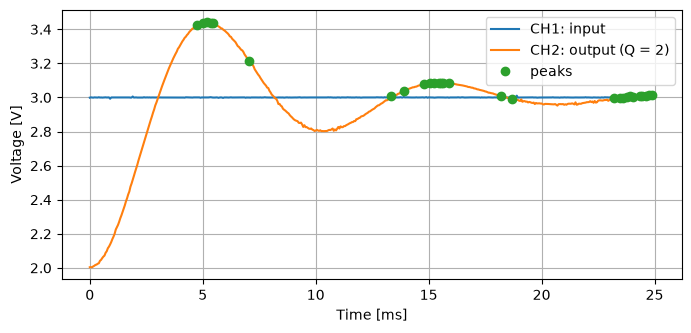

In [8]:
Q_RING = 2

lab.mimic.biquad_lpf(FC, Q_RING)
lab.fg.square(20, 0.5)
t, ch1, ch2 = lab.scope.capture(500)   # 25 ms: until the falling edge
d = np.diff(ch2)
peaks = np.where((d[:-1] > 0) & (d[1:] <= 0))[0] + 1    # local maxima
peaks = peaks[ch2[peaks] > np.median(ch2)]              # the upper ones
if len(peaks) > 1:
    print(f"ringing: {1 / np.mean(np.diff(t[peaks])):.1f} Hz "
          f"(theory {FC * np.sqrt(1 - 1 / (4 * Q_RING ** 2)):.1f} Hz)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (Q = {Q_RING})")
ax.plot(t[peaks] * 1e3, ch2[peaks], "o", label="peaks")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. ゲインがいちばん大きくなる周波数を探す

Q = 2 で、正弦波の周波数を $f_c$ のまわりで変え、ゲインがいちばん大きくなる周波数を探します。$f_c$ ちょうどでしょうか。
<details><summary>ヒント</summary>

`FREQ` を 80 → 85 → 90 → 95 → 100 → 105 → 110 と変えて、ゲインを書き留めてみましょう。山は $f_c$ より少し低い $f_c\sqrt{1 - 1/(2Q^2)}$(約 93.5 Hz)にあり、高さは $Q/\sqrt{1 - 1/(4Q^2)}$(約 2.07)です。$f_c$ でのゲインは Q(2)で、山の頂上より少し低くなります。

</details>

80 Hz: gain 1.853 (theory 1.858)


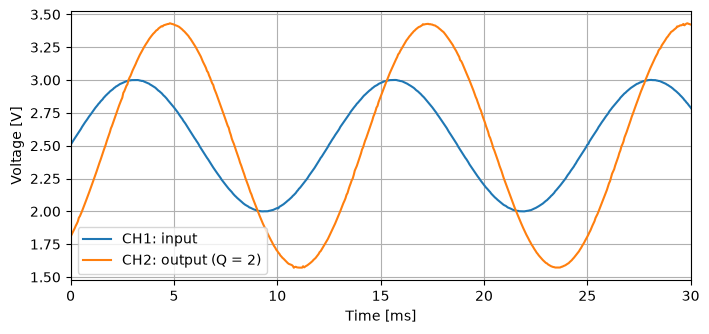

In [9]:
FREQ = 80   # [Hz]

import time
lab.mimic.biquad_lpf(FC, 2)
lab.fg.sine(FREQ, 0.5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
a1, _, _ = fit_sine(t, ch1, FREQ)
a2, _, _ = fit_sine(t, ch2, FREQ)
print(f"{FREQ} Hz: gain {a2 / a1:.3f} (theory {abs(second_order(FREQ, FC, 2, 'lpf')):.3f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (Q = 2)")
ax.set_xlim(0, 30)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 2 次の LPF は、$f_c$ より上を −40 dB/decade で落とす(1 次の 2 倍の傾き)。
- Q で $f_c$ 付近の形が変わる。$f_c$ でのゲインは Q。Q が大きいと方形波で行き過ぎて振動する。
- サレン・キー回路では、R が同じなら $f_c = 1/(2\pi R\sqrt{C_1C_2})$、$Q = \frac{1}{2}\sqrt{C_1/C_2}$。Mimic では `biquad_lpf(fc, q)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()